In [1]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import requests
import scipy
from scipy import stats
from scipy.stats import f_oneway
import random
import math

import warnings
warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")

import sklearn as sk
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split, KFold, cross_val_score


In [2]:
file_path = "ikea.csv"

if not os.path.exists(file_path):
    URL ="https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-11-03/ikea.csv"
    response = requests.get(URL)

    if response.status_code == 200:
        with open(file_path, "wb") as f:
            f.write(response.content)
    else:
        print("Помилка: Не вдалося отримати вміст за URL")
        exit()


df = pd.read_csv(file_path)

In [3]:
df.shape

(3694, 14)

In [4]:
df.head()

,Unnamed: 0,item_id,name,category,price,old_price,sellable_online,link,other_colors,short_description,designer,depth,height,width
0,0,90420332,FREKVENS,Bar furniture,265.0,No old price,True,https://www.ikea.com/sa/en/p/frekvens-bar-tabl...,No,"Bar table, in/outdoor, 51x51 cm",Nicholai Wiig Hansen,NaN,99.0,51.0
1,1,368814,NORDVIKEN,Bar furniture,995.0,No old price,False,https://www.ikea.com/sa/en/p/nordviken-bar-tab...,No,"Bar table, 140x80 cm",Francis Cayouette,NaN,105.0,80.0
2,2,9333523,NORDVIKEN / NORDVIKEN,Bar furniture,2095.0,No old price,False,https://www.ikea.com/sa/en/p/nordviken-nordvik...,No,Bar table and 4 bar stools,Francis Cayouette,NaN,NaN,NaN
3,3,80155205,STIG,Bar furniture,69.0,No old price,True,https://www.ikea.com/sa/en/p/stig-bar-stool-wi...,Yes,"Bar stool with backrest, 74 cm",Henrik Preutz,50.0,100.0,60.0
4,4,30180504,NORBERG,Bar furniture,225.0,No old price,True,https://www.ikea.com/sa/en/p/norberg-wall-moun...,No,"Wall-mounted drop-leaf table, ...",Marcus Arvonen,60.0,43.0,74.0


In [5]:
df.tail()

,Unnamed: 0,item_id,name,category,price,old_price,sellable_online,link,other_colors,short_description,designer,depth,height,width
3689,3689,99157902,ELVARLI,Wardrobes,750.0,SR 820,True,https://www.ikea.com/sa/en/p/elvarli-1-section...,No,"1 section, 92x51x222-350 cm",Ehlén Johansson,50.0,NaN,91.0
3690,3690,9158152,ELVARLI,Wardrobes,1572.0,"SR 1,755",True,https://www.ikea.com/sa/en/p/elvarli-2-section...,No,"2 sections, 135x51x222-350 cm",Ehlén Johansson,50.0,NaN,135.0
3691,3691,59157541,ELVARLI,Wardrobes,924.0,"SR 1,050",True,https://www.ikea.com/sa/en/p/elvarli-2-section...,No,"2 sections, 175x51x222-350 cm",Ehlén Johansson,50.0,NaN,175.0
3692,3692,89157573,ELVARLI,Wardrobes,2745.0,"SR 3,130",True,https://www.ikea.com/sa/en/p/elvarli-3-section...,No,"3 sections, 178x51x222-350 cm",Ehlén Johansson,50.0,NaN,178.0
3693,3693,69157376,ELVARLI,Wardrobes,1231.0,"SR 1,535",True,https://www.ikea.com/sa/en/p/elvarli-2-section...,No,"2 sections, 175x51x222-350 cm",Ehlén Johansson,50.0,NaN,175.0


In [6]:
df.sample(10)

,Unnamed: 0,item_id,name,category,price,old_price,sellable_online,link,other_colors,short_description,designer,depth,height,width
1349,1349,40280843,NORRARYD,Chairs,260.0,SR 325,True,https://www.ikea.com/sa/en/p/norraryd-chair-bl...,No,Chair,Nike Karlsson,51.0,83.0,47.0
2670,2670,10432193,LACK,Tables & desks,29.0,No old price,True,https://www.ikea.com/sa/en/p/lack-glass-top-ma...,No,"Glass top, 55x55 cm",104.321.93 The tabletop in tempered glass is s...,NaN,NaN,55.0
2960,2960,9161569,INGATORP / HENRIKSDAL,Tables & desks,2625.0,No old price,True,https://www.ikea.com/sa/en/p/ingatorp-henriksd...,No,"Table and 4 chairs, 110 cm",IKEA of Sweden/Carina Bengs,NaN,74.0,NaN
2582,2582,39266008,LIDHULT,Sofas & armchairs,5553.0,"SR 6,530",True,https://www.ikea.com/sa/en/p/lidhult-2-seat-so...,No,2-seat sofa-bed,IKEA of Sweden/Henrik Preutz,98.0,102.0,208.0
695,695,80414256,VASSVIKEN,Bookcases & shelving units,100.0,No old price,True,https://www.ikea.com/sa/en/p/vassviken-door-dr...,No,"Door/drawer front, 60x38 cm",IKEA of Sweden,NaN,NaN,NaN
52,52,69326609,SLÄKT,Beds,540.0,No old price,False,https://www.ikea.com/sa/en/p/slaekt-ext-bed-fr...,No,"Ext bed frame with slatted bed base, ...",IKEA of Sweden/Ebba Strandmark,NaN,NaN,91.0
1852,1852,10460888,SMÅGÖRA,Nursery furniture,495.0,No old price,True,https://www.ikea.com/sa/en/p/smagoera-wardrobe...,No,"Wardrobe, 80x50x187 cm",IKEA of Sweden,50.0,187.0,80.0
301,301,20213312,VITTSJÖ,Bookcases & shelving units,395.0,No old price,True,https://www.ikea.com/sa/en/p/vittsjoe-shelving...,No,"Shelving unit, 100x175 cm",Johan Kroon,36.0,175.0,100.0
438,438,59282998,BROR,Bookcases & shelving units,580.0,No old price,True,https://www.ikea.com/sa/en/p/bror-shelving-uni...,No,"Shelving unit, 85x55x190 cm",IKEA of Sweden,55.0,190.0,85.0
2031,2031,40411108,KUDDARNA,Outdoor furniture,75.0,No old price,True,https://www.ikea.com/sa/en/p/kuddarna-seat-cus...,No,"Seat cushion, outdoor, 62x62 cm",IKEA of Sweden,62.0,NaN,62.0


In [3]:
df.columns

Index(['Unnamed: 0', 'item_id', 'name', 'category', 'price', 'old_price',
       'sellable_online', 'link', 'other_colors', 'short_description',
       'designer', 'depth', 'height', 'width'],
      dtype='str')

In [4]:
df.describe()

,Unnamed: 0,item_id,price,depth,height,width
count,3694.000000,3.694000e+03,3694.000000,2231.000000,2706.000000,3105.000000
mean,1846.500000,4.863240e+07,1078.208419,54.379202,101.679970,104.470853
std,1066.510275,2.888709e+07,1374.652494,29.958351,61.097585,71.133771
min,0.000000,5.848700e+04,3.000000,1.000000,1.000000,1.000000
25%,923.250000,2.039057e+07,180.900000,38.000000,67.000000,60.000000
50%,1846.500000,4.928808e+07,544.700000,47.000000,83.000000,80.000000
75%,2769.750000,7.040357e+07,1429.500000,60.000000,124.000000,140.000000
max,3693.000000,9.993262e+07,9585.000000,257.000000,700.000000,420.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3694 entries, 0 to 3693
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         3694 non-null   int64  
 1   item_id            3694 non-null   int64  
 2   name               3694 non-null   str    
 3   category           3694 non-null   str    
 4   price              3694 non-null   float64
 5   old_price          3694 non-null   str    
 6   sellable_online    3694 non-null   bool   
 7   link               3694 non-null   str    
 8   other_colors       3694 non-null   str    
 9   short_description  3694 non-null   str    
 10  designer           3694 non-null   str    
 11  depth              2231 non-null   float64
 12  height             2706 non-null   float64
 13  width              3105 non-null   float64
dtypes: bool(1), float64(4), int64(2), str(7)
memory usage: 378.9 KB


In [5]:
# кількість нульових значень
df.isnull().sum()

Unnamed: 0              0
item_id                 0
name                    0
category                0
price                   0
old_price               0
sellable_online         0
link                    0
other_colors            0
short_description       0
designer                0
depth                1463
height                988
width                 589
dtype: int64

In [6]:
df["category"].unique()
df.category.value_counts()

category
Tables & desks                          612
Bookcases & shelving units              548
Chairs                                  481
Sofas & armchairs                       428
Cabinets & cupboards                    292
Wardrobes                               236
Outdoor furniture                       216
Beds                                    208
TV & media furniture                    190
Chests of drawers & drawer units        125
Children's furniture                    124
Nursery furniture                        97
Bar furniture                            47
Trolleys                                 28
Café furniture                           26
Sideboards, buffets & console tables     23
Room dividers                            13
Name: count, dtype: int64

In [7]:
#  перевірка на наявність дублікатів
df.duplicated().sum()

np.int64(0)

In [8]:
#  перевірка на наявність дублікатів по окремим колонкам
df.duplicated(subset=['item_id', 'name', 'price', 'old_price',
       'sellable_online', 'other_colors','designer', 'depth', 'height', 'width']).sum()


np.int64(732)

In [ ]:
#  # Видалення дублікатів (перевірка показала співпадіння дублікатів)
#  df = df.drop_duplicates(subset=['item_id', 'name', 'price', 'old_price',
#         'sellable_online', 'other_colors','designer', 'depth', 'height', 'width']).reset_index(drop=True)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3694 entries, 0 to 3693
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         3694 non-null   int64  
 1   item_id            3694 non-null   int64  
 2   name               3694 non-null   str    
 3   category           3694 non-null   str    
 4   price              3694 non-null   float64
 5   old_price          3694 non-null   str    
 6   sellable_online    3694 non-null   bool   
 7   link               3694 non-null   str    
 8   other_colors       3694 non-null   str    
 9   short_description  3694 non-null   str    
 10  designer           3694 non-null   str    
 11  depth              2231 non-null   float64
 12  height             2706 non-null   float64
 13  width              3105 non-null   float64
dtypes: bool(1), float64(4), int64(2), str(7)
memory usage: 378.9 KB


In [10]:
# очищення даних по designer
def cleanDesigners(value, removeIKEA=False, emptyValue=np.nan):
    if not isinstance(value, str):
        return value

    if len(value) > 0 and value[0].isdigit():
        return emptyValue

    designers = value.split("/")

    if removeIKEA:
        try:
            designers.remove("IKEA of Sweden")
        except:
            pass
    if len(designers) > 0:
        return "/".join(sorted(designers))
    else:
        return emptyValue
    
designer_clean = df["designer"].apply(cleanDesigners, args=(False, "IKEA of Sweden"))

ikea_df = pd.read_csv("https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-11-03/ikea.csv",
                       index_col=0).drop_duplicates()

ikea_df["designer_clean"] = df["designer"].apply(cleanDesigners, args=(False, "IKEA of Sweden"))

ikea_df["designer_clean"].unique()


<StringArray>
[                                       'Nicholai Wiig Hansen',
                                           'Francis Cayouette',
                                               'Henrik Preutz',
                                              'Marcus Arvonen',
                                                'Carina Bengs',
                                         'K Hagberg/M Hagberg',
                                                 'Sarah Fager',
                                             'Ehlén Johansson',
                                               'Nike Karlsson',
                                             'Maja Ganszyniec',
 ...
                                 'Chris Martin/IKEA of Sweden',
                                              'Wiebke Braasch',
                           'Francis Cayouette/Gustav Carlberg',
                                 'Jomi Evers/Tina Christensen',
                                          'J Karlsson/W Chong',
          'Ehlén Joha

In [11]:
#  кількість дизайнерів по категоріям товарів
unique_designer_per_category = ikea_df.groupby("category")["designer_clean"].nunique()
unique_designer_per_category


category
Bar furniture                            18
Beds                                     46
Bookcases & shelving units               36
Cabinets & cupboards                     30
Café furniture                            8
Chairs                                  117
Chests of drawers & drawer units         19
Children's furniture                     28
Nursery furniture                        15
Outdoor furniture                        32
Room dividers                             7
Sideboards, buffets & console tables      8
Sofas & armchairs                        38
TV & media furniture                     19
Tables & desks                          117
Trolleys                                 11
Wardrobes                                19
Name: designer_clean, dtype: int64

In [12]:
#  групування за категорією, дизайнером та середньою ціною
group_data = ikea_df.groupby(["category", "designer_clean",])["price"].mean().reset_index()
group_data


,category,designer_clean,price
0,Bar furniture,Carina Bengs,370.000000
1,Bar furniture,Caroline/John/Jonas/Paul/Petrus,595.000000
2,Bar furniture,Ehlén Johansson,1149.888889
3,Bar furniture,Francis Cayouette,1121.666667
4,Bar furniture,Henrik Preutz,69.000000
...,...,...,...
563,Wardrobes,J Karlsson/W Chong,49.000000
564,Wardrobes,Jon Karlsson,1095.000000
565,Wardrobes,K Hagberg/M Hagberg,671.666667
566,Wardrobes,Ola Wihlborg,635.750000


In [13]:
# перевірка та очищення даних по old_price 

ikea_df["old_price"] = ikea_df["old_price"].replace("SR", "", regex=True)
ikea_df["old_price"] = ikea_df["old_price"].replace(",", "", regex=True)
ikea_df.tail()


,item_id,name,category,price,old_price,sellable_online,link,other_colors,short_description,designer,depth,height,width,designer_clean
3689,99157902,ELVARLI,Wardrobes,750.0,820,True,https://www.ikea.com/sa/en/p/elvarli-1-section...,No,"1 section, 92x51x222-350 cm",Ehlén Johansson,50.0,NaN,91.0,Ehlén Johansson
3690,9158152,ELVARLI,Wardrobes,1572.0,1755,True,https://www.ikea.com/sa/en/p/elvarli-2-section...,No,"2 sections, 135x51x222-350 cm",Ehlén Johansson,50.0,NaN,135.0,Ehlén Johansson
3691,59157541,ELVARLI,Wardrobes,924.0,1050,True,https://www.ikea.com/sa/en/p/elvarli-2-section...,No,"2 sections, 175x51x222-350 cm",Ehlén Johansson,50.0,NaN,175.0,Ehlén Johansson
3692,89157573,ELVARLI,Wardrobes,2745.0,3130,True,https://www.ikea.com/sa/en/p/elvarli-3-section...,No,"3 sections, 178x51x222-350 cm",Ehlén Johansson,50.0,NaN,178.0,Ehlén Johansson
3693,69157376,ELVARLI,Wardrobes,1231.0,1535,True,https://www.ikea.com/sa/en/p/elvarli-2-section...,No,"2 sections, 175x51x222-350 cm",Ehlén Johansson,50.0,NaN,175.0,Ehlén Johansson


In [14]:
# "old_price" -> float64
ikea_df["old_price"] = pd.to_numeric(ikea_df["old_price"], errors="coerce")

ikea_df["old_price"].dtype

dtype('float64')

In [15]:
# заміна нульових значень на price в "old_price"

ikea_df["old_price"] = ikea_df["old_price"].fillna(ikea_df["price"]).round(2)

ikea_df.head()
ikea_df.tail()

,item_id,name,category,price,old_price,sellable_online,link,other_colors,short_description,designer,depth,height,width,designer_clean
3689,99157902,ELVARLI,Wardrobes,750.0,820.0,True,https://www.ikea.com/sa/en/p/elvarli-1-section...,No,"1 section, 92x51x222-350 cm",Ehlén Johansson,50.0,NaN,91.0,Ehlén Johansson
3690,9158152,ELVARLI,Wardrobes,1572.0,1755.0,True,https://www.ikea.com/sa/en/p/elvarli-2-section...,No,"2 sections, 135x51x222-350 cm",Ehlén Johansson,50.0,NaN,135.0,Ehlén Johansson
3691,59157541,ELVARLI,Wardrobes,924.0,1050.0,True,https://www.ikea.com/sa/en/p/elvarli-2-section...,No,"2 sections, 175x51x222-350 cm",Ehlén Johansson,50.0,NaN,175.0,Ehlén Johansson
3692,89157573,ELVARLI,Wardrobes,2745.0,3130.0,True,https://www.ikea.com/sa/en/p/elvarli-3-section...,No,"3 sections, 178x51x222-350 cm",Ehlén Johansson,50.0,NaN,178.0,Ehlén Johansson
3693,69157376,ELVARLI,Wardrobes,1231.0,1535.0,True,https://www.ikea.com/sa/en/p/elvarli-2-section...,No,"2 sections, 175x51x222-350 cm",Ehlén Johansson,50.0,NaN,175.0,Ehlén Johansson


In [16]:
# аналізуємо дані по габаритним розмірам "depth","height","width".
# замінюємо нульові значення median

imputer = SimpleImputer(strategy="median")
ikea_df["depth"] = imputer.fit_transform(ikea_df[["depth"]]).round(2)
ikea_df["height"] = imputer.fit_transform(ikea_df[["height"]]).round(2)
ikea_df["width"] = imputer.fit_transform(ikea_df[["width"]]).round(2)

ikea_df.isnull().sum()

item_id              0
name                 0
category             0
price                0
old_price            0
sellable_online      0
link                 0
other_colors         0
short_description    0
designer             0
depth                0
height               0
width                0
designer_clean       0
dtype: int64

Описова статистика 

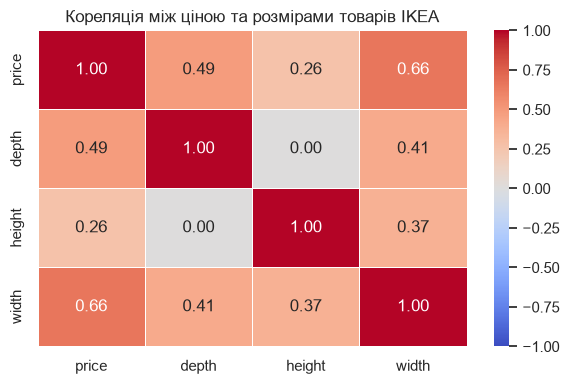

In [17]:
# Ціна - Розміри (Кореляційна матриця)
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 4))

corr_matrix = ikea_df[["price", "depth", "height", "width"]].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Кореляція між ціною та розмірами товарів IKEA")
plt.tight_layout()
plt.show()

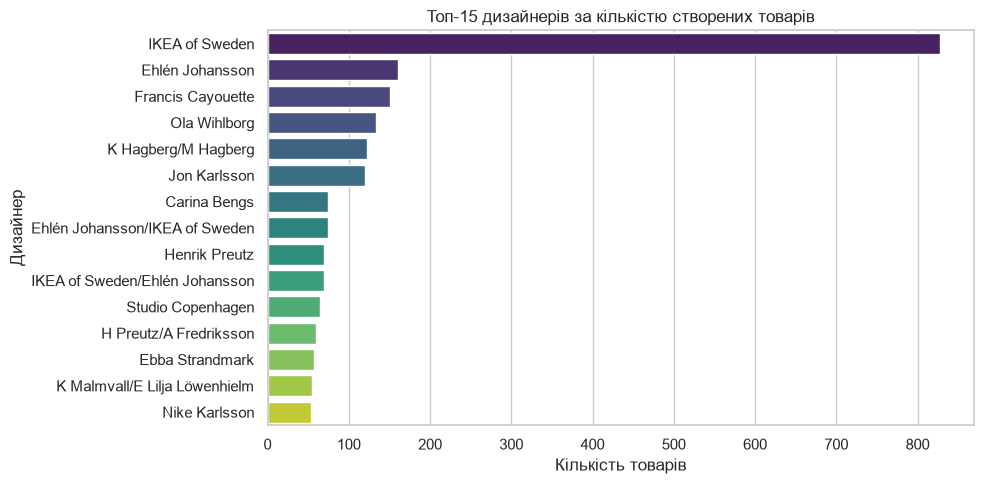

In [23]:
# Кількість товарів по дизайнерам (Тор-15)
top_designers = ikea_df['designer'].value_counts().head(15)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_designers.values, y=top_designers.index, palette='viridis')
plt.title("Топ-15 дизайнерів за кількістю створених товарів")
plt.xlabel("Кількість товарів")
plt.ylabel("Дизайнер")
plt.tight_layout()
plt.show()

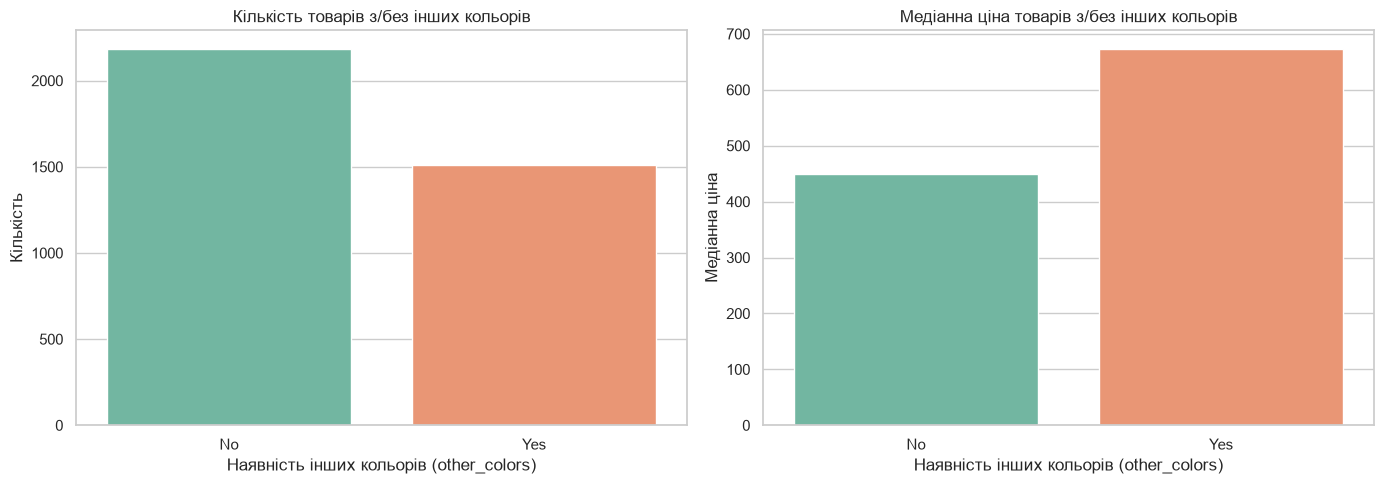

In [20]:
# Кількість та медіання ціна товарів з/без різних кольорів
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=ikea_df, x="other_colors", ax=axes[0], palette="Set2")
axes[0].set_title("Кількість товарів з/без інших кольорів")
axes[0].set_xlabel("Наявність інших кольорів (other_colors)")
axes[0].set_ylabel("Кількість")

sns.barplot(data=ikea_df, x="other_colors", y="price", estimator=np.median, errorbar=None, ax=axes[1], palette="Set2")
axes[1].set_title("Медіанна ціна товарів з/без інших кольорів")
axes[1].set_xlabel("Наявність інших кольорів (other_colors)")
axes[1].set_ylabel("Медіанна ціна")
plt.tight_layout()
plt.show()

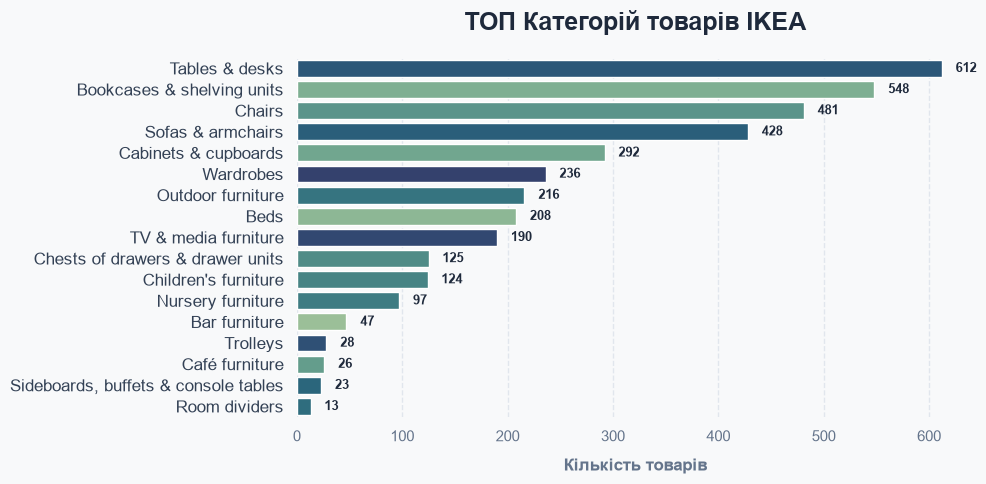

In [ ]:
# Категорії та ціни (ТОП Категорій товарів IKEA)
sns.set_theme(style="white", rc={"axes.facecolor": "#F8F9FA", "figure.facecolor": "#F8F9FA"})
plt.figure(figsize=(10, 5))

category_order = ikea_df["category"].value_counts().index
color_palette = sns.color_palette("crest", n_colors=len(category_order))
ax = sns.countplot( y="category", data=ikea_df, order=category_order, palette=color_palette,hue="category",legend=False)
sns.despine(left=True, bottom=True)
plt.grid(axis='x', linestyle='--', alpha=0.5, color='#CBD5E1') 
plt.title("ТОП Категорій товарів IKEA", fontsize=18, fontweight='bold', pad=20, color='#1E293B')
plt.xlabel("Кількість товарів", fontsize=12, fontweight='semibold', color='#64748B', labelpad=10)
plt.ylabel("", size=0) 
plt.xticks(fontsize=11, color='#64748B')
plt.yticks(fontsize=12, fontweight='medium', color='#334155')

for p in ax.patches:
    width = p.get_width()
    if width > 0: 
        ax.annotate(
            f"{int(width):,}", 
            (width, p.get_y() + p.get_height() / 2),
            ha="left", va="center", xytext=(10, 0), textcoords="offset points",fontsize=9,fontweight='bold',
            color='#1E293B')
plt.tight_layout()
plt.show()

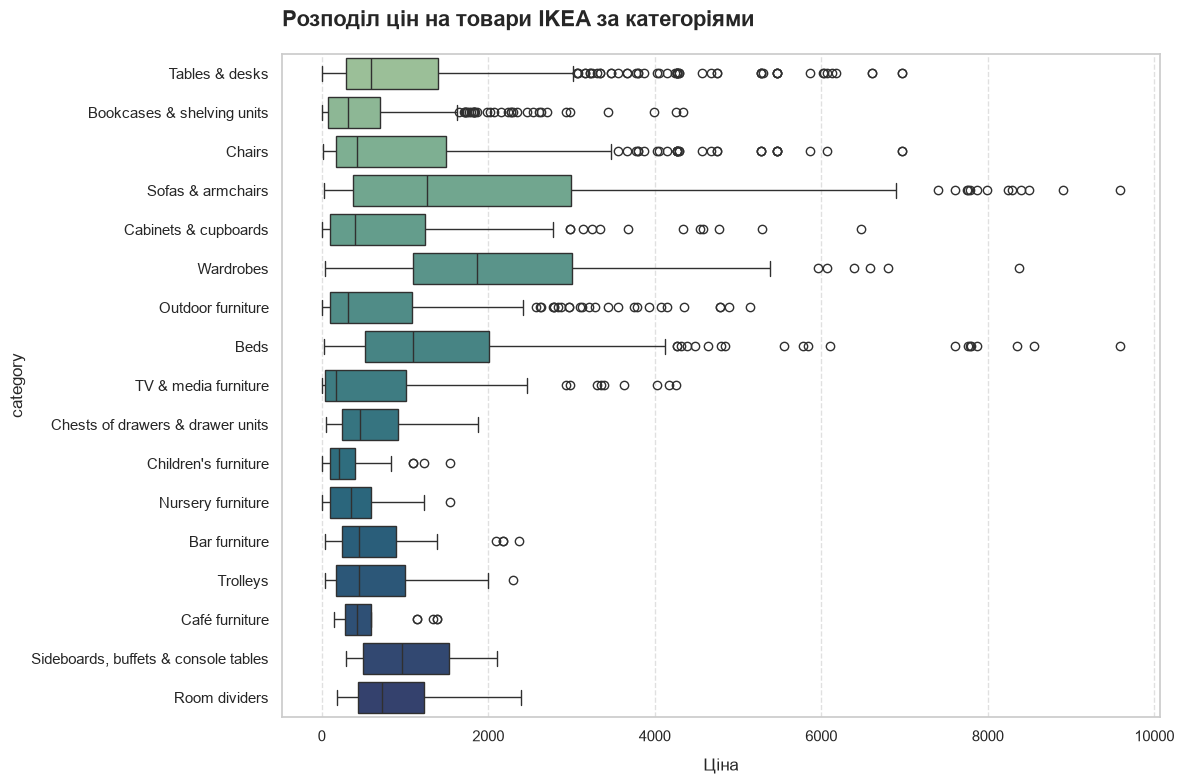

In [22]:
# Розподіл цін на товари IKEA за категоріями
sns.set_theme(style="whitegrid", rc={"grid.linestyle": "--", "grid.alpha": 0.6})

color_palette = sns.color_palette("crest", n_colors=len(category_order))
plt.subplots(figsize=(12,8))
sns.boxplot(
    data=ikea_df,
    x="price",
    y="category",
    order=category_order,
    palette=color_palette)
plt.title("Розподіл цін на товари IKEA за категоріями", fontsize=16, fontweight="bold", pad=20, loc="left")
plt.xlabel("Ціна", fontsize=12, labelpad=10)
# plt.ylabel("Категорія товару", fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

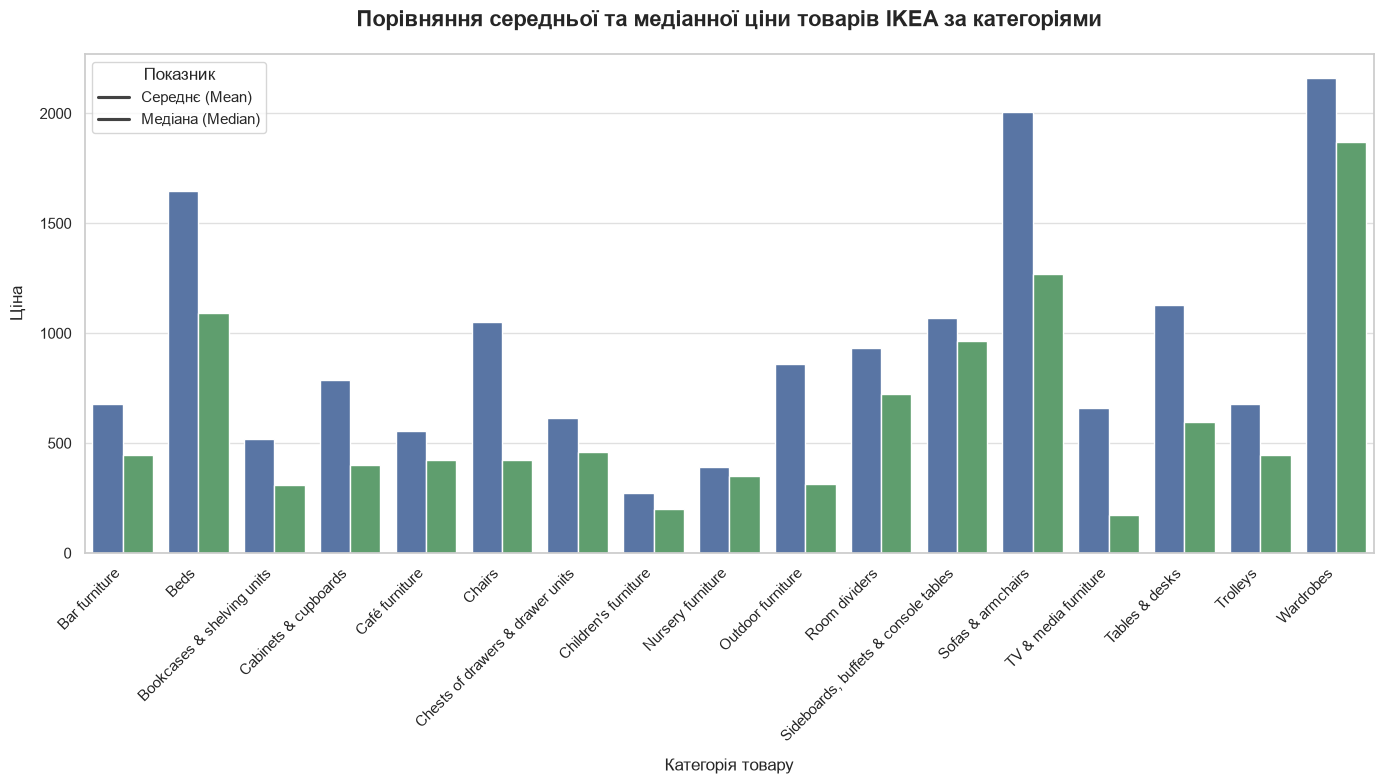

In [ ]:
# графік mean та median price by category
df_stats = (
    ikea_df.groupby("category")["price"].agg(["mean", "median"]).reset_index())
df_melted = df_stats.melt(
    id_vars="category",
    value_vars=["mean", "median"],
    var_name="Stat",
    value_name="Price",)
sns.set_theme(style="whitegrid")  
plt.figure(figsize=(14, 8))
ax = sns.barplot(data=df_melted,x="category",y="Price",hue="Stat",
                 palette=["#4C72B0", "#55A868"])  
plt.title("Порівняння середньої та медіанної ціни товарів IKEA за категоріями",
    fontsize=16,weight="bold",pad=20,)
plt.xlabel("Категорія товару", fontsize=12, labelpad=10)
plt.ylabel("Ціна", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right", fontsize=11)
plt.legend(title="Показник", labels=["Середнє (Mean)", "Медіана (Median)"])
plt.tight_layout()
plt.show()

                                category     max     mean  median    min
0                      Sofas & armchairs  9585.0  2004.02  1268.5   27.0
1                                   Beds  9585.0  1647.43  1093.5   30.0
2                              Wardrobes  8380.0  2162.14  1870.0   45.0
3                         Tables & desks  6965.0  1129.40   595.0    9.0
4                                 Chairs  6965.0  1048.93   425.0   11.4
5                   Cabinets & cupboards  6480.0   789.02   402.0    3.0
6                      Outdoor furniture  5144.0   859.83   313.7    9.0
7             Bookcases & shelving units  4335.0   519.42   310.0    3.0
8                   TV & media furniture  4260.0   659.05   175.0    3.0
9                          Room dividers  2397.0   932.00   725.0  189.0
10                         Bar furniture  2375.0   679.55   445.0   40.0
11                              Trolleys  2295.0   678.52   447.5   39.0
12  Sideboards, buffets & console tables  2100.0  1

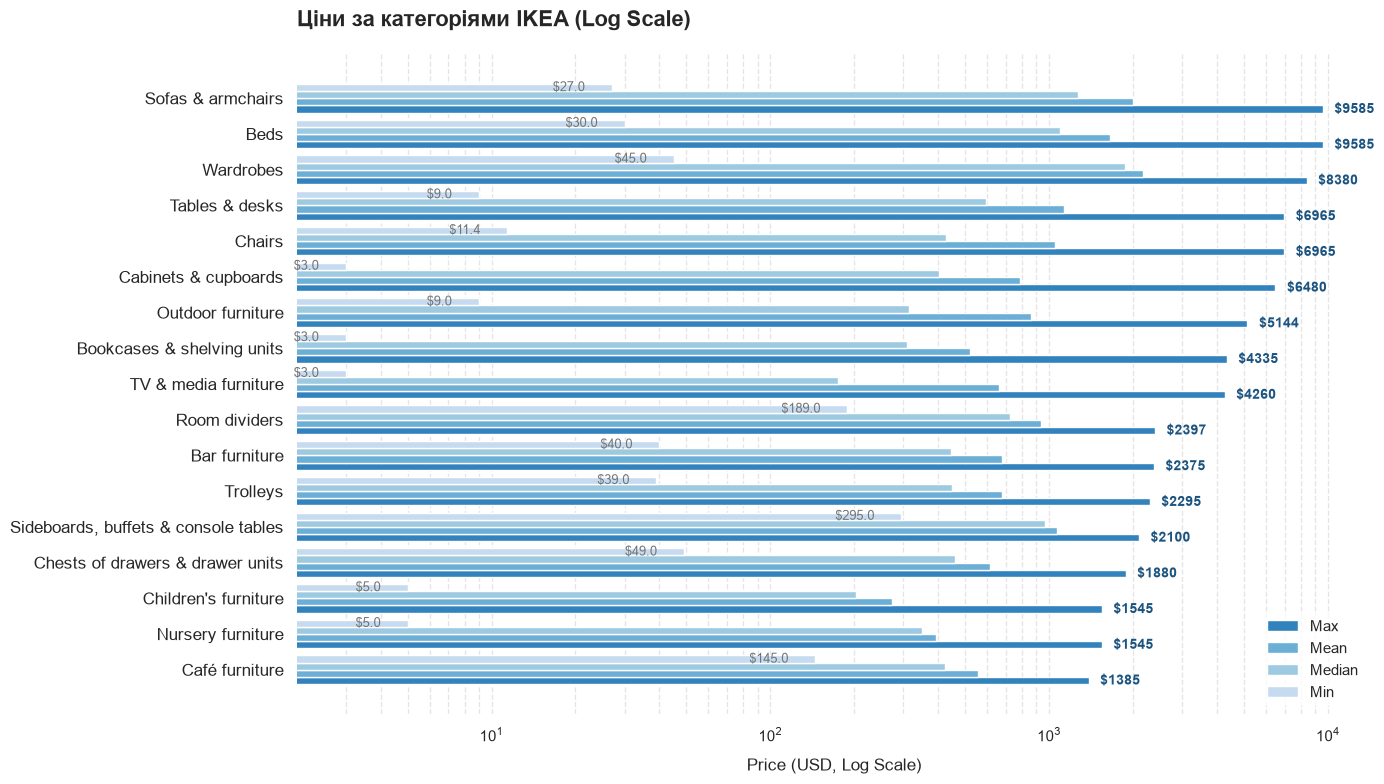

In [24]:
# Графік значень цін по категоріям товару
price_stats = ikea_df.groupby("category")["price"].agg(["max", "mean", "median", "min"]).round(2).reset_index()
price_stats = price_stats.sort_values("max",ascending=False).reset_index(drop=True)
print(price_stats)

sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"

fig, ax = plt.subplots(figsize=(14, 8))
y = np.arange(len(price_stats))
height = 0.2  

ax.barh(y + height * 1.5, price_stats["max"], height, label="Max", color="#3182bd")
ax.barh(y + height * 0.5, price_stats["mean"], height, label="Mean", color="#6baed6")
ax.barh(y - height * 0.5, price_stats["median"], height, label="Median", color="#9ecae1")
ax.barh(y - height * 1.5, price_stats["min"], height, label="Min", color="#c6dbef")

ax.invert_yaxis()
ax.set_xscale("log")

for i, (p_max, p_min) in enumerate(zip(price_stats["max"], price_stats["min"])):
    ax.text(
        p_max * 1.1,
        i + height * 1.5,
        f"${int(p_max)}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color="#1c5480")
    ax.text(
        p_min * 0.8,
        i - height * 1.5,
        f"${p_min:.1f}",
        va="center",
        ha="right",
        fontsize=9,
        color="#737373")

ax.set_title(
    "Ціни за категоріями IKEA (Log Scale)",
    fontsize=16,
    fontweight="bold",
    pad=20,
    loc="left")
ax.set_yticks(y)
ax.set_yticklabels(price_stats["category"], fontsize=12, fontweight="medium")
ax.set_xlabel("Price (USD, Log Scale)", fontsize=12, labelpad=10)

ax.grid(True, which="both", axis="x", linestyle="--", alpha=0.5)
ax.grid(False, axis="y")
sns.despine(left=True, bottom=True)

ax.legend(
    title="",
    title_fontsize="11",
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="none")

plt.tight_layout()
plt.show()

📊 ЗАГАЛЬНА СТАТИСТИКА ДОСТУПНОСТІ ОНЛАЙН
----------------------------------------
Доступно    :  3666 шт. ( 99.2%)
Недоступно  :    28 шт. (  0.8%)
----------------------------------------


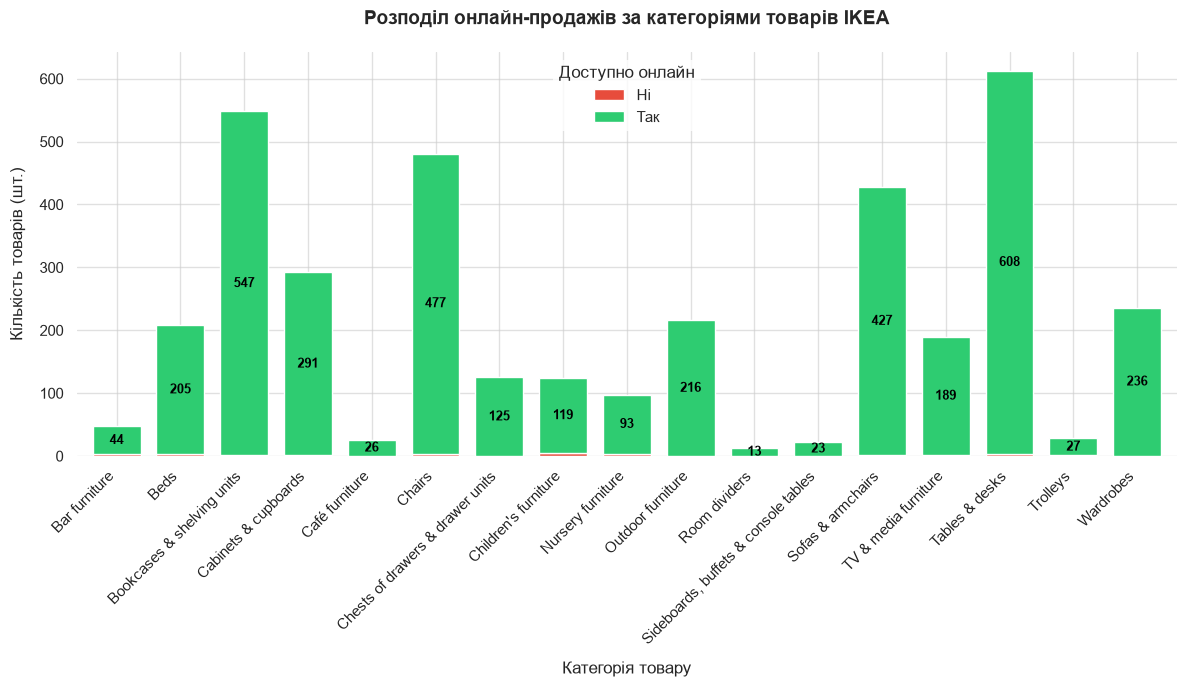

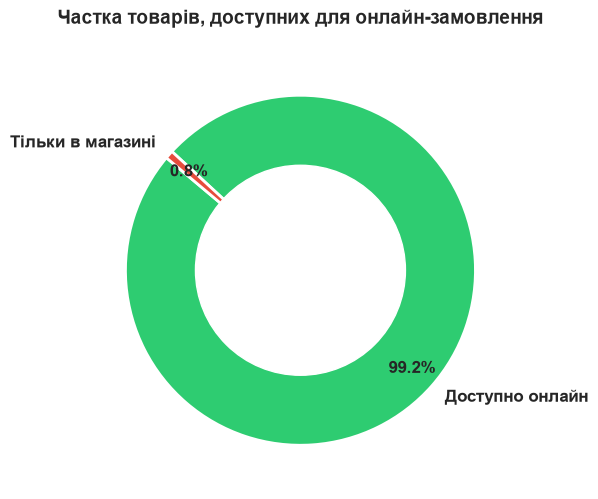

In [25]:
# Категорії та продаж он-лайн
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.titlesize": 14})

sellable_online_counts = ikea_df["sellable_online"].value_counts()
total_count = sellable_online_counts.sum()

print("📊 ЗАГАЛЬНА СТАТИСТИКА ДОСТУПНОСТІ ОНЛАЙН")
print("-" * 40)
for status, count in sellable_online_counts.items():
    pct = (count / total_count) * 100
    status_text = "Доступно" if status else "Недоступно"
    print(f"{status_text:<12}: {count:>5} шт. ({pct:>5.1f}%)")
print("-" * 40)

group_data = ikea_df.groupby(["category", "sellable_online"]).size().unstack(fill_value=0)
colors = ["#e74c3c", "#2ecc71"] 
ax = group_data.plot(kind="bar", stacked=True, figsize=(12, 7), color=colors, width=0.75)

for i in range(len(group_data)):
    cumulative_height = 0
    for col_idx, col in enumerate(group_data.columns):
        height = group_data.iloc[i][col]
        if height > 5: 
            y_pos = cumulative_height + height / 2
            ax.annotate(f"{height:,}",(i, y_pos),ha="center",va="center",color="black",weight="bold",fontsize=9)
        cumulative_height += height

plt.title("Розподіл онлайн-продажів за категоріями товарів IKEA", fontsize=14, weight="bold", pad=20)
plt.xlabel("Категорія товару", fontsize=12, labelpad=10)
plt.ylabel("Кількість товарів (шт.)", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Доступно онлайн", labels=["Ні", "Так"], frameon=True, facecolor="white", edgecolor="none")
sns.despine(left=True, bottom=True) # Прибираємо зайві лінії рамки
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))

labels = ["Доступно онлайн" if index else "Тільки в магазині" for index in sellable_online_counts.index]
plt.pie(
    sellable_online_counts, 
    labels=labels,
    autopct="%1.1f%%", 
    startangle=140,
    colors=["#2ecc71", "#e74c3c"] if sellable_online_counts.index[0] else ["#e74c3c", "#2ecc71"],
    pctdistance=0.85,   
    textprops={"fontsize": 12, "weight": "bold"},
    wedgeprops={"edgecolor": "white", "linewidth": 2, "antialiased": True} # Білі межі між секторами
)

centre_circle = plt.Circle((0,0), 0.60, fc="white")
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
plt.title("Частка товарів, доступних для онлайн-замовлення", fontsize=14, weight="bold", pad=20)
plt.tight_layout()
plt.show()

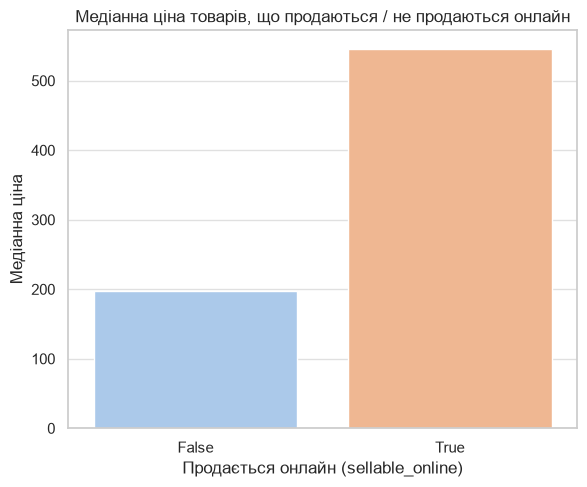

In [26]:
# Медіанна ціна для онлайн_продажів
plt.figure(figsize=(6, 5))
sns.barplot(data=ikea_df, x="sellable_online", y="price", estimator=np.median, errorbar=None, palette="pastel")
plt.title("Медіанна ціна товарів, що продаються / не продаються онлайн")
plt.xlabel("Продається онлайн (sellable_online)")
plt.ylabel("Медіанна ціна")
plt.tight_layout()
plt.show()

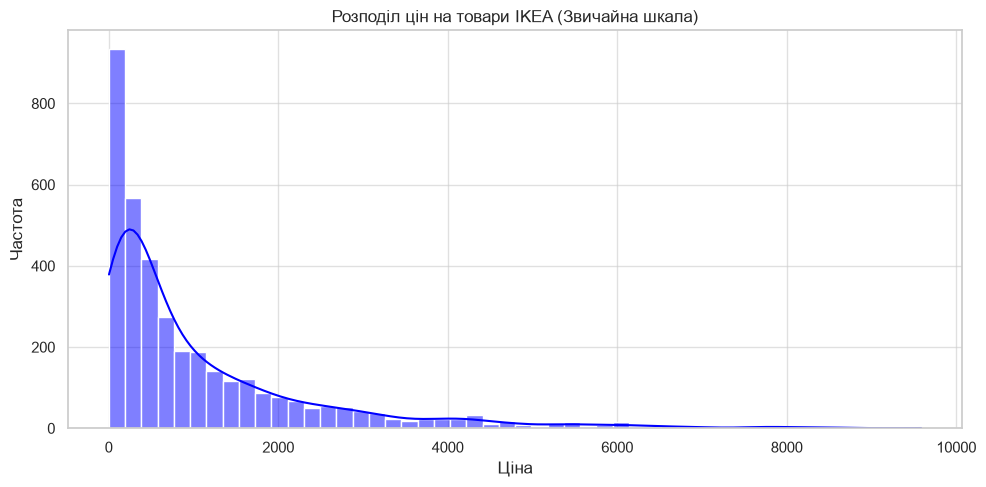

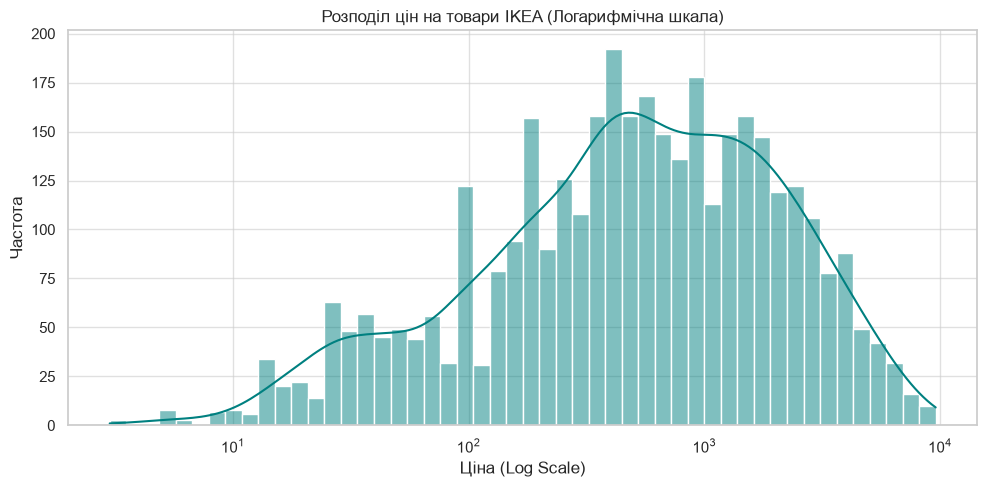

In [ ]:
# Розподіл цін на товари IKEA
plt.figure(figsize=(10, 5))
sns.histplot(data=ikea_df, x="price", kde=True, color="blue", bins=50)
plt.title("Розподіл цін на товари IKEA (Звичайна шкала)")
plt.xlabel("Ціна")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()

# через довгий "хвіст" дорогих товарів, логарифмічна шкала покаже розподіл краще
plt.figure(figsize=(10, 5))
sns.histplot(data=ikea_df, x="price", kde=True, color="teal", log_scale=True, bins=50)
plt.title("Розподіл цін на товари IKEA (Логарифмічна шкала)")
plt.xlabel("Ціна (Log Scale)")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()

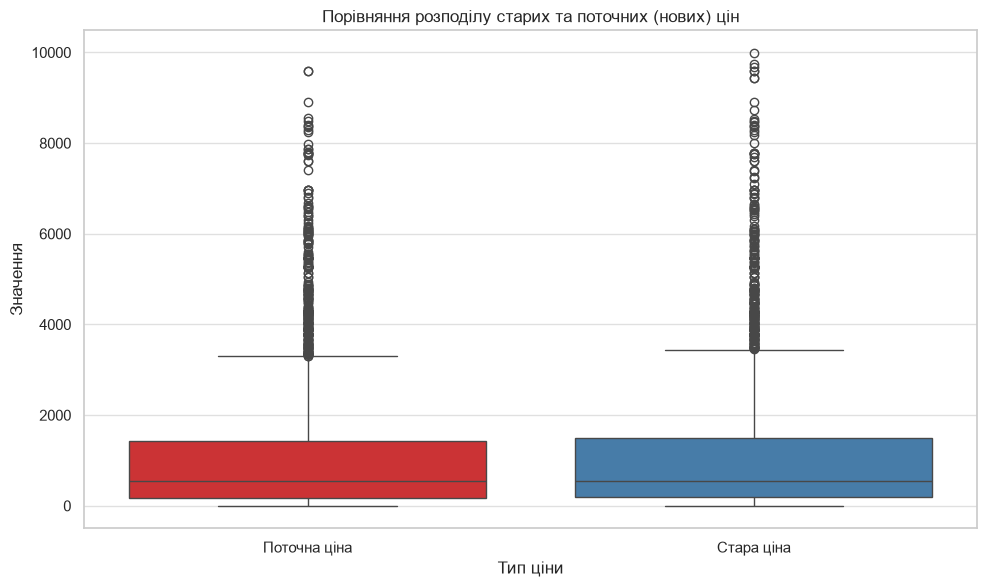

In [28]:
#  Стара / нова ціна (порівняння розподілів)
plt.figure(figsize=(10, 6))
df_prices = ikea_df[["price", "old_price"]].melt(var_name="Price_Type", value_name="Amount")
df_prices["Price_Type"] = df_prices["Price_Type"].map({"price": "Поточна ціна", "old_price": "Стара ціна"})

sns.boxplot(data=df_prices, x="Price_Type", y="Amount", palette="Set1")
plt.title("Порівняння розподілу старих та поточних (нових) цін")
plt.xlabel("Тип ціни")
plt.ylabel("Значення")
plt.tight_layout()
plt.show()

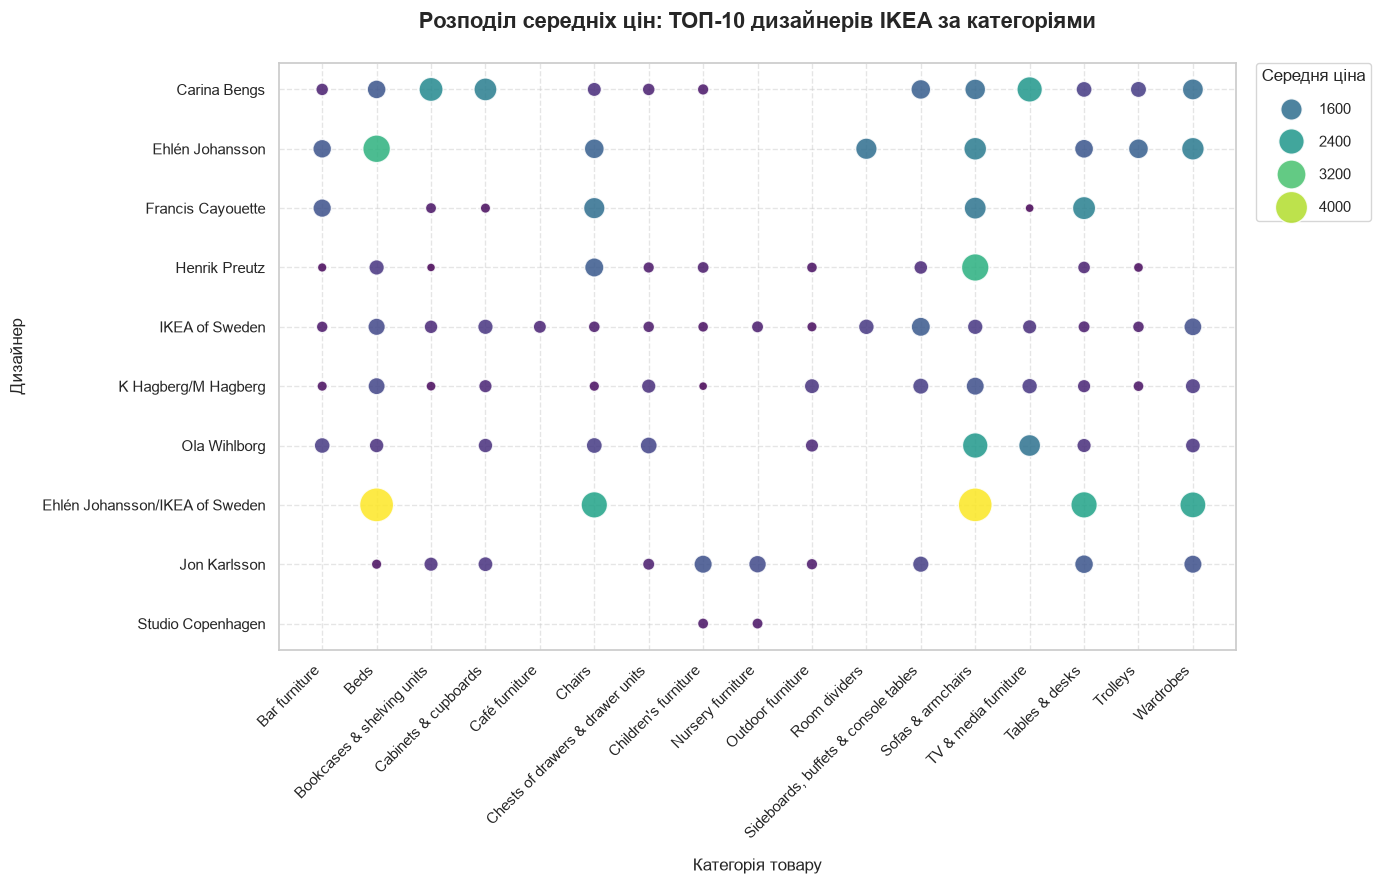

In [27]:
# Розподіл середніх цін: ТОП-10 дизайнерів IKEA за категоріями
top_designers = ikea_df[ikea_df["designer_clean"] !="-"]["designer_clean"].value_counts().nlargest(10)
top_designers_data = ikea_df[ikea_df["designer_clean"].isin(top_designers.index)]
group_data = top_designers_data.groupby(["category", "designer_clean"])["price"].mean().reset_index()
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 9))
sc = sns.scatterplot( data=group_data, x="category", y="designer_clean", size="price", hue="price",
    sizes=(40, 600), palette="viridis",  alpha=0.85,  edgecolor="w",linewidth=1)
h, l = sc.get_legend_handles_labels()
plt.legend(h[1:6],l[1:6],title="Середня ціна",bbox_to_anchor=(1.02, 1),loc="upper left",borderaxespad=0,labelspacing=1.2)
plt.title("Розподіл середніх цін: ТОП-10 дизайнерів IKEA за категоріями",fontsize=16,fontweight="bold",pad=25)
plt.xlabel("Категорія товару", fontsize=12, labelpad=12)
plt.ylabel("Дизайнер", fontsize=12, labelpad=12)
plt.xticks(rotation=45, ha="right")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

3.   На основі EDA та вашого здорового глузду виберіть дві гіпотези, які ви хочете перевірити/проаналізувати. Для кожної гіпотези перерахуйте нульову гіпотезу та інші можливі альтернативні гіпотези, розробіть тести для їх розрізнення та виконайте їх. Опишіть результати.

In [28]:
# Гіпотеза 1: Різниця в цінах між категоріями. => Немає суттєвої різниці в цінах між категоріями
# (H0): Немає суттєвої різниці в цінах між категоріями (середні ціни рівні).
# (H1): Існує значна різниця в цінах між категоріями (хоча б одна категорія відрізняється).
categories = ikea_df["category"].unique()
category_price = [ikea_df[ikea_df["category"] == category]["price"] for category in categories]
f_stat, p_value = f_oneway(*category_price)

print(f"---ANOVA тест: F-statistics = {f_stat}, p-value = {p_value}---")
if p_value < 0.05:
    print("Відхиити нульову гіпотезу: Існує значна різниця в цінах між категоріями.")
else:
    print("Нульову гіпотезу не відхилено: Немає суттєвої різниці в цінах між категоріями")

print("\n" + "="*50 + "\n")
# ТЕСТ 1: Непараметричний критерій Краскела-Волліса (Kruskal-Wallis)
# підходить для цін, оскільки вони зазвичай не мають нормального розподілу
h_stat, p_value_kruskal = stats.kruskal(*category_price)

print("---тест Краскела-Волліса ---")
print(f"H-statistics = {h_stat}, p-value = {p_value_kruskal}")
if p_value_kruskal < 0.05:
    print("Відхилити нульову гіпотезу: Медіани цін між категоріями суттєво відрізняються.")
else:
    print("Нульову гіпотезу не відхилено: Немає медіанної різниці в цінах між категоріями.")
print("\n" + "="*50 + "\n")

# ТЕСТ 2: Попарний тест Тьюкі (Tukey's HSD) 
# Показує, які САМЕ категорії відрізняються між собою (виводить скориговані p-value для кожної пари)
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
print("---Попарні порівняння (Tukey HSD) ---")
tukey = pairwise_tukeyhsd(endog=ikea_df['price'],
                          groups=ikea_df['category'],
                          alpha=0.05)
print(tukey.summary()) 

---ANOVA тест: F-statistics = 44.175971461002675, p-value = 1.7017332054158932e-127---
Відхиити нульову гіпотезу: Існує значна різниця в цінах між категоріями.


---тест Краскела-Волліса ---
H-statistics = 684.7748456684609, p-value = 2.2447596280864974e-135
Відхилити нульову гіпотезу: Медіани цін між категоріями суттєво відрізняються.


---Попарні порівняння (Tukey HSD) ---
                                  Multiple Comparison of Means - Tukey HSD, FWER=0.05                                  
               group1                               group2                 meandiff  p-adj    lower      upper   reject
-----------------------------------------------------------------------------------------------------------------------
                       Bar furniture                                 Beds   967.8795 0.0003   262.6453 1673.1137   True
                       Bar furniture           Bookcases & shelving units  -160.1371    1.0  -823.8239  503.5496  False
                      

In [29]:
# Гіпотеза 2: Вплив інших кольорів на ціну товару
# (НО): Наявність інших кольорів не впливає на ціну товарую
# (Н1): Ціна товару залежить від наявності інших кольорів

# 1. Тест Манна-Уітні для порівняння розподілу цін товарів з різною наявністю інших колорів
from scipy.stats import mannwhitneyu
from scipy.stats import ttest_ind

color_items = ikea_df[ikea_df["other_colors"] == "Yes"]["price"]
mono_items = ikea_df[ikea_df["other_colors"] == "No"]["price"]

statistic, p_value = mannwhitneyu(color_items, mono_items)
print("---Тест Манна-Уітні---:")
print(f"Статистика тесту: {statistic}")
print(f"p_value: {p_value}")
if p_value < 0.05:
    print("Результат: Відхиляємо нульову гіпотезу, є статистично значущі відмінності")
else:
    print("Результат: Немає достатніх доказів для відхилення нульової гіпотези")
print("\n" + "="*50 + "\n")

# 2. t-тест для порівняння цін на товари з іншими кольорами та без інших кольорів
statistic, p_value =ttest_ind(color_items, mono_items)
print("---t-тест---:")
print(f"Статистика тесту: {statistic}")
print(f"p_value: {p_value}")
if p_value < 0.05:
    print("Результат: Відхиляємо нульову гіпотезу, є статистично значущі відмінності")
else:
    print("Результат: Немає достатніх доказів для відхилення нульової гіпотези")



---Тест Манна-Уітні---:
Статистика тесту: 1867534.5
p_value: 8.029293283507823e-12
Результат: Відхиляємо нульову гіпотезу, є статистично значущі відмінності


---t-тест---:
Статистика тесту: 5.055784750204881
p_value: 4.494472015246448e-07
Результат: Відхиляємо нульову гіпотезу, є статистично значущі відмінності


4. Машинне навчання


In [31]:
#1. Видалення стовпців які не впливають на ціну товару...
columns_drop =['item_id','name','link','short_description','designer','old_price']
new_df = ikea_df.drop(columns=columns_drop, inplace=False)

In [32]:
# 2. кодування категоріальних даних у числові (бінарні) значення.
new_df['other_colors'] = new_df['other_colors'].map({'Yes': 1, 'No': 0})

X = new_df[['category', 'other_colors', 'depth','height', 'width', 'designer_clean']]
y = new_df['price']

X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

numeric_transformer = Pipeline(steps=[
    ("scalar", StandardScaler())])
categorical_transfofmer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
col_preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, ['depth','height', 'width','other_colors']),
    ("categorical", categorical_transfofmer, ['category','designer_clean'])])

# Модель регресії DecisionTreeRegressor
model_tree = Pipeline(steps=[
    ("col_preprocessor", col_preprocessor),
    ("tree", DecisionTreeRegressor(max_depth=10, random_state=42))])
model_tree.fit(X_train,y_train)
model_tree_predict = model_tree.predict(X_test)

r2 = model_tree.score(X_test, y_test)
mae = mean_absolute_error(model_tree_predict, y_test)
mse = mean_squared_error(model_tree_predict, y_test)
rmse = np.sqrt(mse)

print("DecisionTreeRegressor R^2 : {:.5f}".format(r2))
print("DecisionTreeRegressor MAE : {:.5f}".format(mae))
print("DecisionTreeRegressor MSE : {:.5f}".format(mse))
print("DecisionTreeRegressor RMSE : {:.5f}".format(rmse))
print("\n" + "="*50 + "\n")

# Модель регресії KNeighborsRegressor
model_knn = Pipeline(steps=[
    ("col_preprocessor",col_preprocessor),
    ("knn_regressor", KNeighborsRegressor())])
model_knn.fit(X_train, y_train)
model_knn_pred = model_knn.predict(X_test)

r2_knn = r2_score(y_test, model_knn_pred)
print(f"KNeighborsRegressor R^2: {r2_knn:.3f}")
mse_knn =np.mean((model_knn_pred - y_test)**2)
print("KNeighborsRegressor Mean Squered Error: {:.2f}".format(mse_knn))
rmse_knn = np.sqrt(mse_knn)
print("KNeighborsRegressor RMSE: {:.2f}".format(rmse_knn))
print("\n" + "="*50 + "\n")

# Модель регресії RandomForestRegressor
model_rf = Pipeline(steps=[
    ("col_preprocessor",col_preprocessor),
    ("rf_regressor", RandomForestRegressor(random_state=42))])
model_rf.fit(X_train, y_train)
model_rf_pred = model_rf.predict(X_test)

r2_rf = r2_score(y_test, model_rf_pred)
print(f"RandomForestRegressor R^2: {r2_rf:.3f}")
mse_rf =np.mean((model_rf_pred - y_test)**2)
print("RandomForestRegressor Mean Squered Error: {:.2f}".format(mse_rf))
rmse_rf = np.sqrt(mse_rf)
print("RandomForestRegressor RMSE: {:.2f}".format(rmse_rf))
print("\n" + "="*50 + "\n")

# Модель регресії BaggingRegressor
model_bagging = Pipeline(steps=[
    ("col_preprocessor",col_preprocessor),
    ("bagging_regressor", BaggingRegressor(estimator=DecisionTreeRegressor()))])
model_bagging.fit(X_train, y_train)
model_bagging_pred = model_bagging.predict(X_test)

r2_bagging = r2_score(y_test, model_bagging_pred)
print(f"BaggingRegressor R^2: {r2_bagging:.3f}")
mse_bagging =np.mean((model_bagging_pred - y_test)**2)
print("BaggingRegressor Mean Squered Error: {:.2f}".format(mse_bagging))
rmse_bagging = np.sqrt(mse_bagging)
print("BaggingRegressor RMSE: {:.2f}".format(rmse_bagging))

DecisionTreeRegressor R^2 : 0.74534
DecisionTreeRegressor MAE : 393.72978
DecisionTreeRegressor MSE : 490855.50177
DecisionTreeRegressor RMSE : 700.61081


KNeighborsRegressor R^2: 0.774
KNeighborsRegressor Mean Squered Error: 434767.51
KNeighborsRegressor RMSE: 659.37


RandomForestRegressor R^2: 0.809
RandomForestRegressor Mean Squered Error: 368150.00
RandomForestRegressor RMSE: 606.75


BaggingRegressor R^2: 0.805
BaggingRegressor Mean Squered Error: 375665.04
BaggingRegressor RMSE: 612.92


In [33]:
# Порівняльна таблиця моделей:
mae_knn = mean_absolute_error(y_test, model_knn_pred)
mae_rf = mean_absolute_error(y_test, model_rf_pred)
mae_bagging = mean_absolute_error(y_test, model_bagging_pred)

results = {
    "Model": ["DecisionTree", "KNeighbors", "RandomForest", "Bagging"],
    "R2": [r2, r2_knn, r2_rf, r2_bagging],
    "MAE": [mae, mae_knn, mae_rf, mae_bagging],
    "MSE": [mse, mse_knn, mse_rf, mse_bagging],
    "RMSE": [rmse, rmse_knn, rmse_rf, rmse_bagging]
}

# сортуємо за R2 (від найкращого до найгіршого)
df_results = pd.DataFrame(results).sort_values(by="R2", ascending=False)

print("\nПорівняльна таблиця моделей:")
print(df_results.to_string(index=False))

best_model_name = df_results.iloc[0]["Model"]
print(f"\n🏆 Найкраща модель за показником R^2: {best_model_name}")


Порівняльна таблиця моделей:
       Model       R2        MAE           MSE       RMSE
RandomForest 0.809000 305.544669 368150.000793 606.753657
     Bagging 0.805101 305.300505 375665.043336 612.915201
  KNeighbors 0.774438 366.553424 434767.509421 659.369024
DecisionTree 0.745339 393.729781 490855.501766 700.610806

🏆 Найкраща модель за показником R^2: RandomForest


findfont: Failed to find font weight semibold, now using 700.


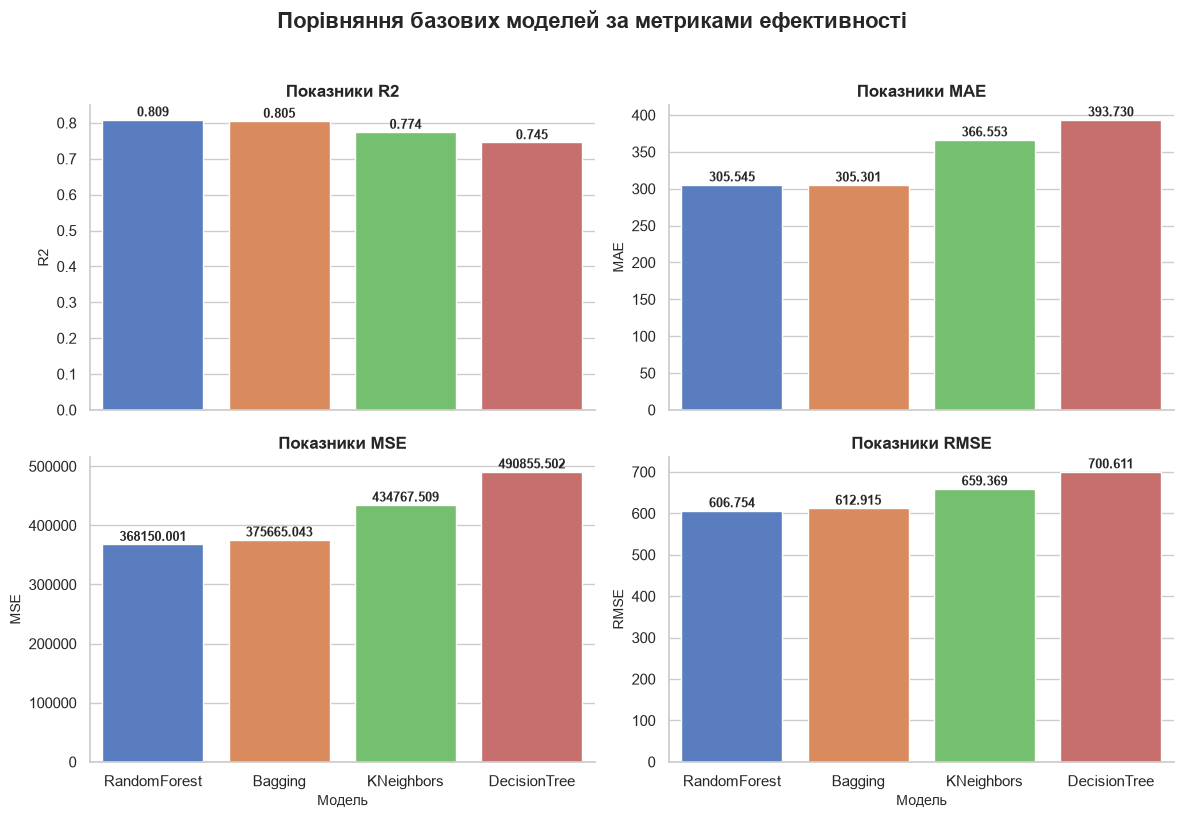

In [34]:
# Порівняння базових моделей за метриками ефективності
sns.set_theme(style="whitegrid")
df_long = df_results.melt(id_vars='Model', value_vars=['R2', 'MAE', 'MSE', 'RMSE'], 
                          var_name='Metric', value_name='Value')
g = sns.catplot(data=df_long, x='Model', y='Value', col='Metric', col_wrap=2, kind='bar', hue='Model', 
                palette='muted', height=4, aspect=1.5, sharey=False,legend=False)
g.fig.suptitle('Порівняння базових моделей за метриками ефективності', fontsize=16, fontweight='bold', y=1.02)
for ax in g.axes.flat:
    current_metric = ax.get_title().split(' = ')[-1]
    ax.set_title(f"Показники {current_metric}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Модель", fontsize=10)
    ax.set_ylabel(current_metric, fontsize=10)
    for p in ax.patches:
        height = p.get_height()
        if pd.notna(height):
            ax.annotate(f"{height:.3f}", 
                        (p.get_x() + p.get_width() / 2., height), 
                        ha='center', va='center', 
                        xytext=(0, 5), 
                        textcoords='offset points', 
                        fontsize=9, fontweight='semibold')

plt.tight_layout()
plt.show()

In [35]:
# GridSearchCV для найкращої моделі

model_rf = Pipeline(steps=[
    ('col_preprocessor', col_preprocessor), 
    ('rf_regressor', RandomForestRegressor(random_state=42))
])

param_grid = {
    'rf_regressor__n_estimators':[50, 150, 200, 300],
    'rf_regressor__max_depth': [5, 10, 20],
    'rf_regressor__min_samples_split':[5],
    'rf_regressor__min_samples_leaf': [1, 2]
}
grid_search = GridSearchCV(estimator=model_rf, param_grid=param_grid, cv=5, scoring='r2', n_jobs=-1,verbose=1)
grid_search.fit(X_train, y_train)
print(f"Найкращі параметри: {grid_search.best_params_}\n")
best_model = grid_search.best_estimator_
model_rf_pred = best_model.predict(X_test)

r2_rf = r2_score(y_test, model_rf_pred)
print(f"RandomForestRegressor R^2: {r2_rf:.3f}")
mse_rf = np.mean((model_rf_pred - y_test) ** 2)
print("RandomForestRegressor Mean Squared Error: {:.2f}".format(mse_rf))
rmse_rf = np.sqrt(mse_rf)
print("RandomForestRegressor RMSE: {:.2f}".format(rmse_rf))


Fitting 5 folds for each of 24 candidates, totalling 120 fits
Найкращі параметри: {'rf_regressor__max_depth': 20, 'rf_regressor__min_samples_leaf': 1, 'rf_regressor__min_samples_split': 5, 'rf_regressor__n_estimators': 300}

RandomForestRegressor R^2: 0.805
RandomForestRegressor Mean Squared Error: 376822.32
RandomForestRegressor RMSE: 613.86



Results of Optimized RandomForestRegressor Feature Importance:
                Importance  Importance (%)
width             0.555280       55.527975
designer_clean    0.191711       19.171105
depth             0.129657       12.965724
height            0.057269        5.726913
category          0.055187        5.518673
other_colors      0.010896        1.089610


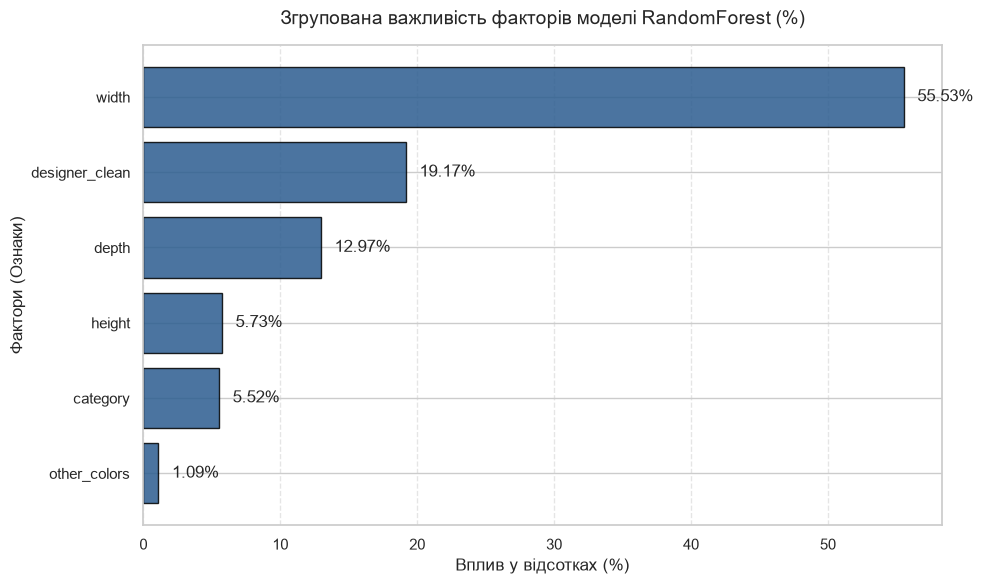

In [36]:
# Дослідження впливу факторів моделі моделі RandomForest всередині GridSearchCV
feature_importances = best_model.named_steps["rf_regressor"].feature_importances_
numeric_features = ["depth", "height", "width", "other_colors"]
categorical_features = ["category", "designer_clean"]

# Отримуємо назви згенерованих категоріальних стовпчиків після OneHotEncoder
cat_columns = (
    best_model.named_steps["col_preprocessor"]
    .named_transformers_["categorical"]
    .named_steps["onehot"]
    .get_feature_names_out(categorical_features))

# Об'єднуємо всі фінальні назви стовпчиків у тому ж порядку, що й у ColumnTransformer
final_columns = np.concatenate([numeric_features, cat_columns])

# Створення початкового DataFrame важливості
importance_df = pd.DataFrame(
    {"Feature": final_columns, "Importance": feature_importances}
).sort_values(by="Importance", ascending=False)

# Ручне групування важливості за початковими 6 факторами з Х
grouped_importances = {
    key: 0
    for key in [
        "category",
        "designer_clean",
        "other_colors",
        "depth",
        "height",
        "width"]}
for _, row in importance_df.iterrows():
    for key in grouped_importances:
        if row["Feature"].startswith(key):
            grouped_importances[key] += row["Importance"]
            break

#  Формування фінального DataFrame та розрахунок відсотків
grouped_importances_df = pd.DataFrame.from_dict(
    grouped_importances, orient="index", columns=["Importance"])
grouped_importances_df = grouped_importances_df.sort_values(
    by="Importance", ascending=False)
grouped_importances_df["Importance (%)"] = (
    grouped_importances_df["Importance"] / grouped_importances_df["Importance"].sum()) * 100

print("\nResults of Optimized RandomForestRegressor Feature Importance:")
print(grouped_importances_df)

# 6. Побудова візуалізації на основі згрупованих даних
plt.figure(figsize=(10, 6))
# Сортуємо для графіка по зростанню
plot_df = grouped_importances_df.sort_values(by="Importance", ascending=True)
bars = plt.barh(
    plot_df.index,
    plot_df["Importance (%)"],
    color="#2b5c8f",
    edgecolor="black",
    alpha=0.85,
)
plt.title(
    "Згрупована важливість факторів моделі RandomForest (%)",
    fontsize=14,
    pad=15,
)
plt.xlabel("Вплив у відсотках (%)", fontsize=12)
plt.ylabel("Фактори (Ознаки)", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 1, bar.get_y() + bar.get_height() / 2, f"{width:.2f}%", va="center")
plt.tight_layout()
plt.show()

RandomForestRegressor R^2: 0.809
RandomForestRegressor Mean Squared Error: 368150.00
RandomForestRegressor RMSE: 606.75


=== РЕЗУЛЬТАТИ КРОС-ВАЛІДАЦІЇ ===
CV R^2:  0.827 (+/- 0.017)
CV MSE:  325068.90 (+/- 31833.72)
CV RMSE: 569.43 (+/- 28.63)


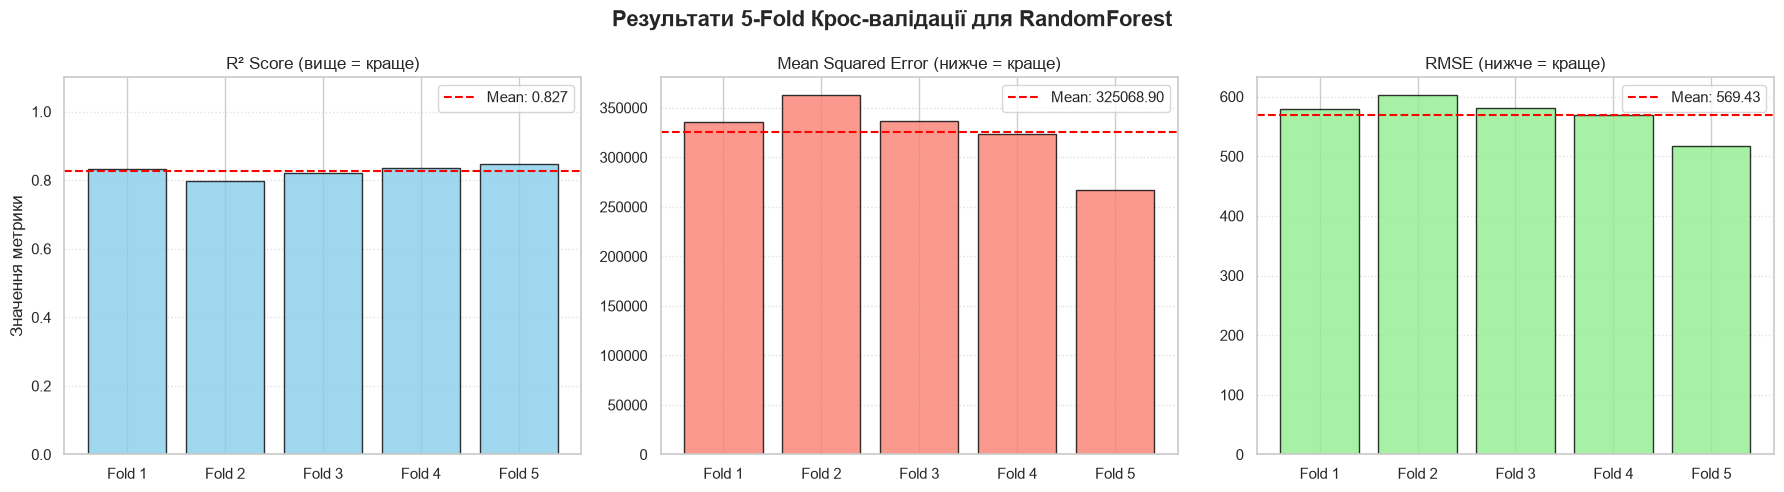

In [37]:
# cross_val_score
# Створення пайплайну та навчання 
model_rf = Pipeline(steps=[
    ('col_preprocessor', col_preprocessor), 
    ('rf_regressor', RandomForestRegressor(random_state=42))
])

# Навчання моделі та прогноз на тестовій вибірці
model_rf.fit(X_train, y_train)
model_rf_pred = model_rf.predict(X_test)

# Виведення початкових метрик
r2_rf = r2_score(y_test, model_rf_pred)
print(f"RandomForestRegressor R^2: {r2_rf:.3f}")

mse_rf = np.mean((model_rf_pred - y_test)**2)
print("RandomForestRegressor Mean Squared Error: {:.2f}".format(mse_rf))

rmse_rf = np.sqrt(mse_rf)
print("RandomForestRegressor RMSE: {:.2f}".format(rmse_rf))
print("\n" + "="*50 + "\n")

# 2. Розрахунок Cross-Validation Scores (R², MSE, RMSE)
# Налаштовуємо 5-fold крос-валідацію
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Крос-валідація для R^2
cv_r2 = cross_val_score(model_rf, X_train, y_train, cv=kf, scoring='r2')

# Крос-валідація для MSE 
cv_mse = -cross_val_score(model_rf, X_train, y_train, cv=kf, scoring='neg_mean_squared_error')

# Крос-валідація для RMSE
cv_rmse = np.sqrt(cv_mse)

# Виведення середніх значень крос-валідації 
print("=== РЕЗУЛЬТАТИ КРОС-ВАЛІДАЦІЇ ===")
print(f"CV R^2:  {np.mean(cv_r2):.3f} (+/- {np.std(cv_r2):.3f})")
print(f"CV MSE:  {np.mean(cv_mse):.2f} (+/- {np.std(cv_mse):.2f})")
print(f"CV RMSE: {np.mean(cv_rmse):.2f} (+/- {np.std(cv_rmse):.2f})")

# 3. Візуалізація результатів крос-валідації 
folds = [f"Fold {i+1}" for i in range(5)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Результати 5-Fold Крос-валідації для RandomForest', fontsize=16, fontweight='bold')

# Графік 1: R^2 Score
axes[0].bar(folds, cv_r2, color='skyblue', edgecolor='black', alpha=0.8)
axes[0].axhline(np.mean(cv_r2), color='red', linestyle='--', linewidth=1.5, label=f'Mean: {np.mean(cv_r2):.3f}')
axes[0].set_title('R² Score (вище = краще)', fontsize=12)
axes[0].set_ylabel('Значення метрики')
axes[0].set_ylim(0, 1.1)
axes[0].grid(axis='y', linestyle=':', alpha=0.6)
axes[0].legend()

# Графік 2: MSE
axes[1].bar(folds, cv_mse, color='salmon', edgecolor='black', alpha=0.8)
axes[1].axhline(np.mean(cv_mse), color='red', linestyle='--', linewidth=1.5, label=f'Mean: {np.mean(cv_mse):.2f}')
axes[1].set_title('Mean Squared Error (нижче = краще)', fontsize=12)
axes[1].grid(axis='y', linestyle=':', alpha=0.6)
axes[1].legend()

# Графік 3: RMSE
axes[2].bar(folds, cv_rmse, color='lightgreen', edgecolor='black', alpha=0.8)
axes[2].axhline(np.mean(cv_rmse), color='red', linestyle='--', linewidth=1.5, label=f'Mean: {np.mean(cv_rmse):.2f}')
axes[2].set_title('RMSE (нижче = краще)', fontsize=12)
axes[2].grid(axis='y', linestyle=':', alpha=0.6)
axes[2].legend()
plt.tight_layout()
plt.show()

findfont: Failed to find font weight semibold, now using 700.


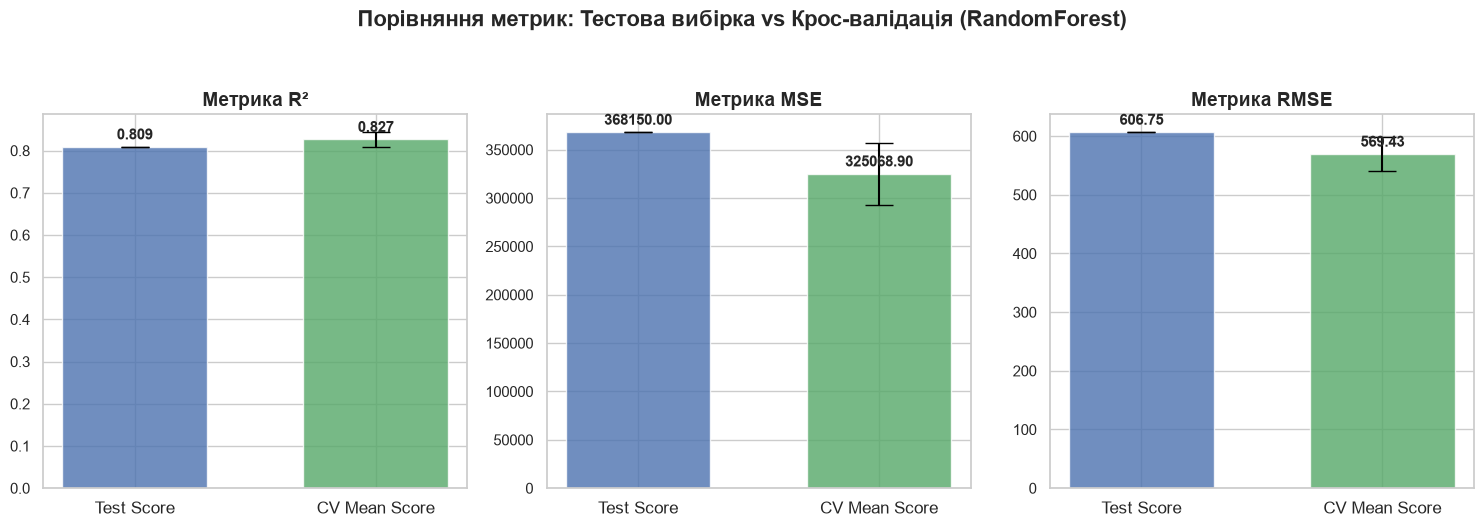

In [38]:
# 1. Збір даних для побудови графіка
metrics = ["R²", "MSE", "RMSE"]
test_metrics = [r2_rf, mse_rf, rmse_rf]
cv_means = [np.mean(cv_r2), np.mean(cv_mse), np.mean(cv_rmse)]
cv_stds = [np.std(cv_r2), np.std(cv_mse), np.std(cv_rmse)]

# Налаштування стилю
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=False)
fig.suptitle(
    "Порівняння метрик: Тестова вибірка vs Крос-валідація (RandomForest)",
    fontsize=16,
    fontweight="bold",
    y=1.05,
)

# Побудова окремого графіка для кожної метрики через різницю в масштабах
for i, metric in enumerate(metrics):
    ax = axes[i]
    x_pos = np.arange(2)
    bars_y = [test_metrics[i], cv_means[i]]
    error_y = [0, cv_stds[i]]  # Помилка (std) є тільки для крос-валідації

    # Малювання стовпчиків
    colors = ["#4C72B0", "#55A868"]
    bars = ax.bar(
        x_pos,
        bars_y,
        yerr=error_y,
        align="center",
        alpha=0.8,
        ecolor="black",
        capsize=10,
        color=colors,
        width=0.6,
    )

    # Налаштування осей
    ax.set_title(f"Метрика {metric}", fontsize=14, fontweight="semibold")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(["Test Score", "CV Mean Score"], fontsize=12)

    # Додавання значень над стовпчиками
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.3f}" if metric == "R²" else f"{height:.2f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),  # 3 точки вертикального зсуву
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
        )

plt.tight_layout()
plt.show()

In [39]:
df_results = pd.DataFrame({
    'Метрика': metrics,
    'Тест': test_metrics,
    'CV Среднее': cv_means,
    'CV Разброс (std)': cv_stds
})
print(df_results)

  Метрика           Тест     CV Среднее  CV Разброс (std)
0      R²       0.809000       0.826634          0.017087
1     MSE  368150.000793  325068.902433      31833.717704
2    RMSE     606.753657     569.428945         28.628289
